In [2]:
import numpy as np
from helpers.model import *
from helpers.plotting import *

ModuleNotFoundError: No module named 'helpers'

In [ ]:
# Performance Goal 1

Omega_h = np.sqrt(m*g/(4*k_T)) # rad/s
u_h = k_Q * Omega_h**2 * np.ones(4) # N m

x0_c = 0
y0_c = 0
z0_c = 1

vx0_h = 0
vy0_h = 0
vz0_h = 0

phi0_h = 0
theta0_h = 0
psi0_h = 0

omega1_h = 0
omega2_h = 0
omega3_h = 0

E0_h = 0

# <x, y, z, vx, vy, vz, phi, theta, psi, omega1, omega2, omega3, Omega1, Omega2, Omega3, Omega4, E>
r_initial_h = np.array([0, 0, 1, vx0_h, vy0_h, vz0_h, phi0_h, theta0_h, psi0_h, omega1_h, omega2_h, omega3_h, Omega_h, Omega_h, Omega_h, Omega_h, E0_h])

f_hover = lambda r, t : state_dot(r, t, u_h)

r_hover, times_h = forward_euler(f_hover, r_initial_h, 120, 0.001)

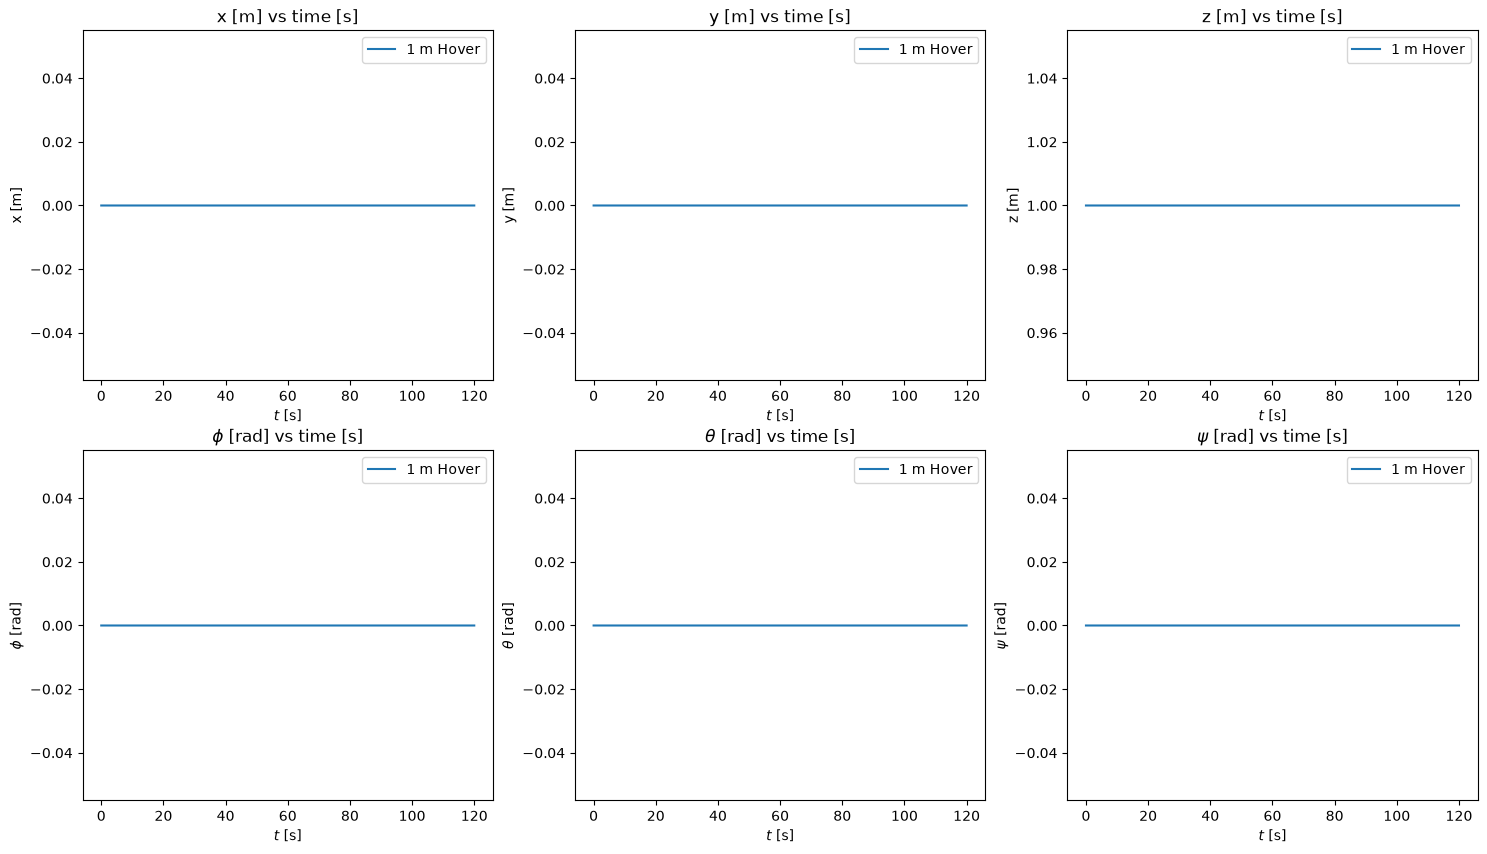

In [ ]:
fig1 = plotDegreesOfFreedom(times_h, r_hover, '1 m Hover')

In [ ]:
E_hover_f = r_hover[-1][16]

print(f'Calculated energy used at the end is {E_hover_f/3600} Wh which matches the predicted.')

Calculated energy used at the end is 4.884124171033732 Wh which matches the predicted.


In [ ]:
# Test 2
a_c = 0.125 # m/s^2

x0_c = 2
y0_c = 0
z0_c = 1

vx0_c = 0
vy0_c = 0.5
vz0_c = 0

phi0_c = -np.atan2(a_c, g)
theta0_c = 0
psi0_c = np.pi/2

omega1_c = 0
omega2_c = 0.25*np.sin(phi0_c)
omega3_c = 0.25*np.cos(phi0_c)

T_c = m*np.sqrt(g**2 + a_c**2)
M1_c = (I3 - I2)*omega2_c*omega3_c

T0_c = np.array([T_c/4, T_c/4 + M1_c/(2*l), T_c/4, T_c/4 - M1_c/(2*l)])
Omega0_c = np.sqrt(T0_c/k_T)

E0_c = 0

u_c = k_Q * Omega0_c**2 # N m

f_circle = lambda r, t : state_dot(r, t, u_c)

r0_c = np.array([x0_c, y0_c, z0_c, vx0_c, vy0_c, vz0_c, phi0_c, theta0_c, psi0_c, omega1_c, omega2_c, omega3_c, Omega0_c[0], Omega0_c[1], Omega0_c[2], Omega0_c[3], E0_c])

r_circle, times_c = forward_euler(f_circle, r0_c, 60, 0.001)

x_c_desired = 2*np.cos(0.25*times_c)
y_c_desired = 2*np.sin(0.25*times_c)

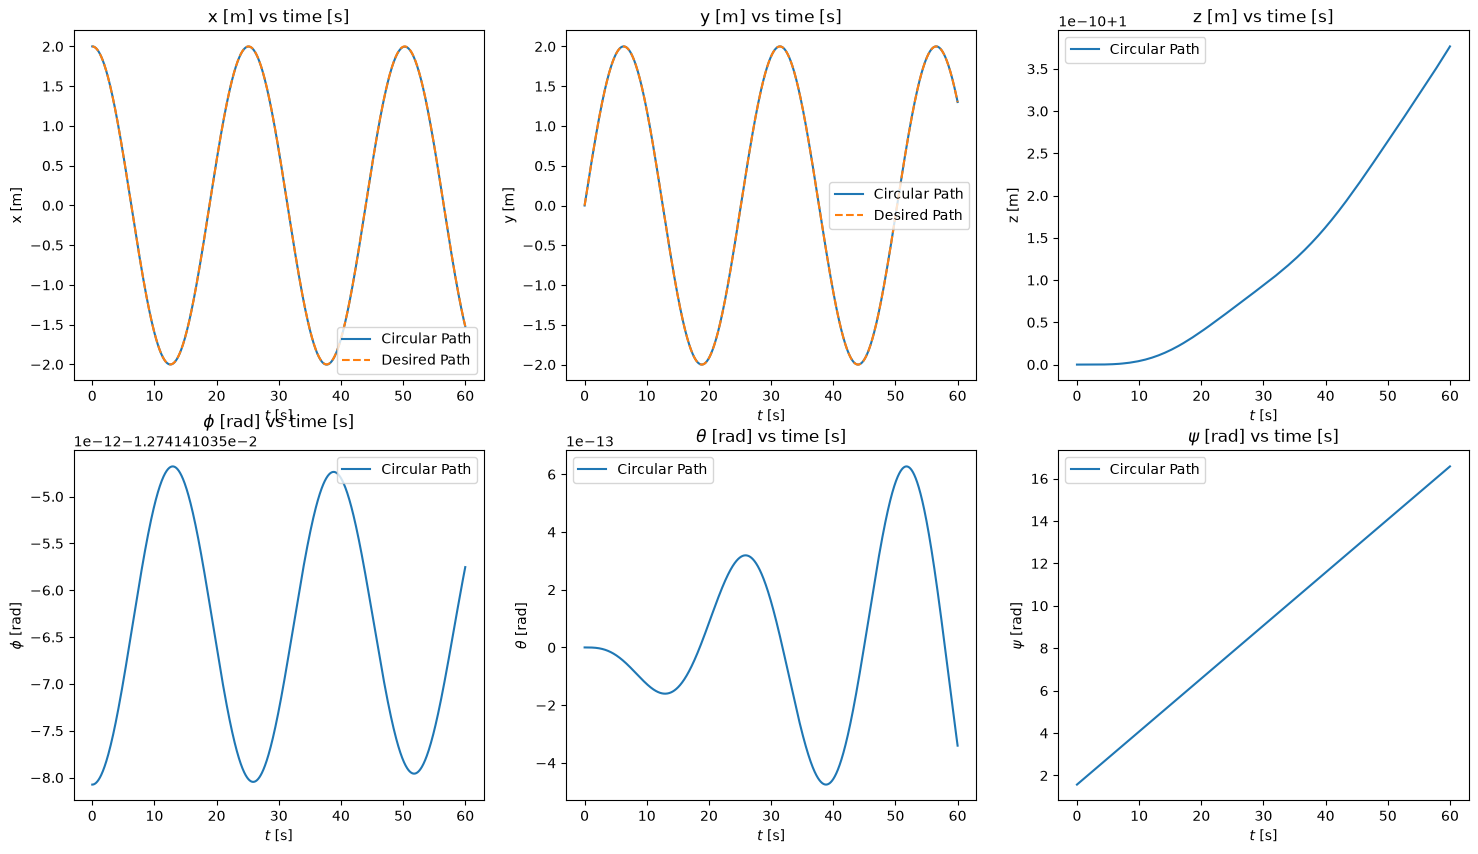

In [ ]:
fig2 = plotDegreesOfFreedom(times_c, r_circle, 'Circular Path')
axes = fig2.axes

axes[0].plot(times_c, x_c_desired, label='Desired Path', ls='--')
axes[0].legend()
axes[1].plot(times_c, y_c_desired, label='Desired Path', ls='--')
axes[1].legend()

In [ ]:
max_x_c_error = np.max(np.abs(r_circle[:,0] - x_c_desired))
max_y_c_error = np.max(np.abs(r_circle[:,0] - y_c_desired))
E_circle_f = r_circle[-1][16]

print(f'Maximum error x: {max_x_c_error}')
print(f'Maximum error y: {max_x_c_error}')
print(f'Energy used: {E_circle_f} J')

Maximum error x: 0.003424778617650892
Maximum error y: 0.003424778617650892
Energy used: 8792.45749467119 J


In [ ]:
# AI
# Test 3 - Phase 1: Ascension from (0, 0, z_g) to (0, 0, 1)

z_g = 0.15  # m (touchdown/ground CoM height)
z_target_a = 1.0  # m

x0_a = 0
y0_a = 0
z0_a = z_g

vx0_a = 0
vy0_a = 0
vz0_a = 0

phi0_a = 0
theta0_a = 0
psi0_a = 0

omega1_a = 0
omega2_a = 0
omega3_a = 0

Omega0_a = np.zeros(4)
E0_a = 0

# Simple altitude PD controller -> desired thrust -> desired rotor speed -> motor torque
Kp_z = 12.0
Kd_z = 7.0
K_omega = 0.002

def u_ascend(r, t):
  z = r[2]
  vz = r[5]
  Omega = r[12:16]

  # Desired vertical acceleration -> total thrust -> per-motor speed
  az_cmd = Kp_z * (z_target_a - z) + Kd_z * (0.0 - vz)
  T_d = max(m * (az_cmd + g), 0.0)
  Omega_d = np.sqrt((T_d / 4.0) / k_T)

  # Aerodynamic drag feedforward + rotor speed error
  Q_i = k_Q * Omega**2
  u = Q_i + K_omega * (Omega_d - Omega)
  return np.clip(u, 0.0, 0.10)  # Enforce [0, 0.10] N*m limit


def f_ascend(r, t):
  dr = state_dot(r, t, u_ascend(r, t))
  # Ground support: hold on ground until upward thrust exceeds weight
  if r[2] <= z_g and dr[5] < 0:
    dr[2] = 0.0
    dr[5] = 0.0
  return dr


r0_a = np.array([x0_a, y0_a, z0_a, vx0_a, vy0_a, vz0_a, phi0_a, theta0_a, psi0_a, omega1_a, omega2_a, omega3_a, Omega0_a[0], Omega0_a[1], Omega0_a[2], Omega0_a[3], E0_a])

r_ascend, times_a = forward_euler(f_ascend, r0_a, 4, 0.001)

In [ ]:
# AI
# Test 3 - Phase 2: Translation from (0, 0, 1) to (5, 0, 1) in 5 s (1 m/s avg)

r0_t1 = r_ascend[-1].copy()

T_leg1 = 5.0        # s (5 m / 1 m/s = 5 s)
x_start_t1 = 0.0
x_end_t1 = 5.0
y_target_t1 = 0.0
z_target_t1 = 1.0
psi_target_t1 = 0.0

# Controller gains
Kp_pos = np.array([6.0, 6.0, 12.0])
Kd_pos = np.array([4.5, 4.5, 7.0])
Kp_att = np.array([35.0, 35.0, 15.0])
Kd_att = np.array([10.0, 10.0, 6.0])
K_omega = 0.002

def u_trans1(r, t):
    pos = r[0:3]
    vel = r[3:6]
    phi, theta, psi = r[6:9]
    w = r[9:12]
    Omega = r[12:16]

    # Smooth rest-to-rest minimum-jerk trajectory for x(t) over T_leg1 = 5 s
    tau = np.clip(t / T_leg1, 0.0, 1.0)
    dx = x_end_t1 - x_start_t1

    xd = x_start_t1 + dx * (10*tau**3 - 15*tau**4 + 6*tau**5)
    vxd = (dx / T_leg1) * (30*tau**2 - 60*tau**3 + 30*tau**4)
    axd = (dx / T_leg1**2) * (60*tau - 180*tau**2 + 120*tau**3)

    pos_d = np.array([xd, y_target_t1, z_target_t1])
    vel_d = np.array([vxd, 0.0, 0.0])
    acc_d = np.array([axd, 0.0, 0.0])

    # Outer loop: position PD + feedforward -> thrust & desired angles
    a_cmd = acc_d + Kp_pos * (pos_d - pos) + Kd_pos * (vel_d - vel)
    T_d = max(m * (a_cmd[2] + g) / (np.cos(theta) * np.cos(phi)), 0.0)
    phi_d = (a_cmd[0] * np.sin(psi) - a_cmd[1] * np.cos(psi)) / g
    theta_d = (a_cmd[0] * np.cos(psi) + a_cmd[1] * np.sin(psi)) / g

    # Inner loop: attitude PD -> desired body moments
    psi_err = (psi_target_t1 - psi + np.pi) % (2 * np.pi) - np.pi
    att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
    M_d = np.array([I1, I2, I3]) * (Kp_att * att_err - Kd_att * w)

    # Control allocation -> desired rotor speeds
    T1_d = T_d / 4.0 - M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
    T2_d = T_d / 4.0 + M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]
    T3_d = T_d / 4.0 + M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
    T4_d = T_d / 4.0 - M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]

    Omega_d = np.sqrt(np.maximum(np.array([T1_d, T2_d, T3_d, T4_d]), 0.0) / k_T)

    # Rotor loop: drag feedforward + speed tracking -> motor torque
    Q_i = k_Q * Omega**2
    u = Q_i + K_omega * (Omega_d - Omega)
    return np.clip(u, 0.0, 0.10)

f_trans1 = lambda r, t: state_dot(r, t, u_trans1(r, t))

# Run slightly past 5.0 s (e.g., 6.0 s) if you want extra settling time to hit v = 0 cleanly
r_trans1, times_t1 = forward_euler(f_trans1, r0_t1, 6.0, 0.001)

In [ ]:
# AI
# Test 3 - Phase 3: Stopped +pi/2 yaw rotation at (5, 0, 1)

r0_yaw = r_trans1[-1].copy()

T_yaw = 3.0  # s (duration for smooth 90-degree yaw turn)
pos_target_yaw = np.array([5.0, 0.0, 1.0])
psi_start_yaw = 0.0
psi_end_yaw = np.pi / 2.0

# Controller gains
Kp_pos = np.array([6.0, 6.0, 12.0])
Kd_pos = np.array([4.5, 4.5, 7.0])
Kp_att = np.array([35.0, 35.0, 15.0])
Kd_att = np.array([10.0, 10.0, 6.0])
K_omega = 0.002


def u_yaw(r, t):
  pos = r[0:3]
  vel = r[3:6]
  phi, theta, psi = r[6:9]
  w = r[9:12]
  Omega = r[12:16]

  # Smooth rest-to-rest minimum-jerk yaw ramp from 0 to +pi/2
  tau = np.clip(t / T_yaw, 0.0, 1.0)
  dpsi = psi_end_yaw - psi_start_yaw

  psi_d = psi_start_yaw + dpsi * (10 * tau**3 - 15 * tau**4 + 6 * tau**5)
  wz_d = (dpsi / T_yaw) * (30 * tau**2 - 60 * tau**3 + 30 * tau**4)

  # Outer loop: hold position fixed at (5, 0, 1)
  a_cmd = Kp_pos * (pos_target_yaw - pos) + Kd_pos * (np.zeros(3) - vel)
  T_d = max(m * (a_cmd[2] + g) / (np.cos(theta) * np.cos(phi)), 0.0)
  phi_d = (a_cmd[0] * np.sin(psi) - a_cmd[1] * np.cos(psi)) / g
  theta_d = (a_cmd[0] * np.cos(psi) + a_cmd[1] * np.sin(psi)) / g

  # Inner loop: track desired yaw and yaw rate
  psi_err = (psi_d - psi + np.pi) % (2 * np.pi) - np.pi
  att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
  w_d = np.array([0.0, 0.0, wz_d])
  M_d = np.array([I1, I2, I3]) * (Kp_att * att_err + Kd_att * (w_d - w))

  # Control allocation -> desired rotor speeds
  T1_d = T_d / 4.0 - M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T2_d = T_d / 4.0 + M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]
  T3_d = T_d / 4.0 + M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T4_d = T_d / 4.0 - M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]

  Omega_d = np.sqrt(np.maximum(np.array([T1_d, T2_d, T3_d, T4_d]), 0.0) / k_T)

  # Rotor loop -> motor torque
  Q_i = k_Q * Omega**2
  u = Q_i + K_omega * (Omega_d - Omega)
  return np.clip(u, 0.0, 0.10)


f_yaw = lambda r, t: state_dot(r, t, u_yaw(r, t))

# Run 4.0 s (3.0 s turn + 1.0 s settle)
r_yaw, times_y = forward_euler(f_yaw, r0_yaw, 4.0, 0.001)

In [ ]:
# AI
# Test 3 - Phase 4: Translation from (5, 0, 1) to (5, 5, 1) with psi = +pi/2

r0_t2 = r_yaw[-1].copy()

T_leg2 = 5.0  # s
x_target_t2 = 5.0
y_start_t2 = 0.0
y_end_t2 = 5.0
z_target_t2 = 1.0
psi_target_t2 = np.pi / 2.0


def u_trans2(r, t):
  pos = r[0:3]
  vel = r[3:6]
  phi, theta, psi = r[6:9]
  w = r[9:12]
  Omega = r[12:16]

  # Smooth rest-to-rest minimum-jerk trajectory for y(t)
  tau = np.clip(t / T_leg2, 0.0, 1.0)
  dy = y_end_t2 - y_start_t2

  yd = y_start_t2 + dy * (10 * tau**3 - 15 * tau**4 + 6 * tau**5)
  vyd = (dy / T_leg2) * (30 * tau**2 - 60 * tau**3 + 30 * tau**4)
  ayd = (dy / T_leg2**2) * (60 * tau - 180 * tau**2 + 120 * tau**3)

  pos_d = np.array([x_target_t2, yd, z_target_t2])
  vel_d = np.array([0.0, vyd, 0.0])
  acc_d = np.array([0.0, ayd, 0.0])

  a_cmd = acc_d + Kp_pos * (pos_d - pos) + Kd_pos * (vel_d - vel)
  T_d = max(m * (a_cmd[2] + g) / (np.cos(theta) * np.cos(phi)), 0.0)
  phi_d = (a_cmd[0] * np.sin(psi) - a_cmd[1] * np.cos(psi)) / g
  theta_d = (a_cmd[0] * np.cos(psi) + a_cmd[1] * np.sin(psi)) / g

  psi_err = (psi_target_t2 - psi + np.pi) % (2 * np.pi) - np.pi
  att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
  M_d = np.array([I1, I2, I3]) * (Kp_att * att_err - Kd_att * w)

  T1_d = T_d / 4.0 - M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T2_d = T_d / 4.0 + M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]
  T3_d = T_d / 4.0 + M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T4_d = T_d / 4.0 - M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]

  Omega_d = np.sqrt(np.maximum(np.array([T1_d, T2_d, T3_d, T4_d]), 0.0) / k_T)
  Q_i = k_Q * Omega**2
  u = Q_i + K_omega * (Omega_d - Omega)
  return np.clip(u, 0.0, 0.10)


f_trans2 = lambda r, t: state_dot(r, t, u_trans2(r, t))
r_trans2, times_t2 = forward_euler(f_trans2, r0_t2, 6.0, 0.001)

In [ ]:
# AI
# Test 3 - Phase 5: Controlled vertical descent from (5, 5, 1) to z_g = 0.15 m
# Requirement: -0.01 <= vz <= 0 m/s -> 0.85 m descent takes >= 85 s (using 90 s for smooth ramp)

r0_desc = r_trans2[-1].copy()

z_g = 0.15
T_desc = 90.0  # s (keeps peak descent rate within -0.01 m/s limit)
x_target_d = 5.0
y_target_d = 5.0
z_start_d = 1.0
psi_target_d = np.pi / 2.0


def u_descend(r, t):
  pos = r[0:3]
  vel = r[3:6]
  phi, theta, psi = r[6:9]
  w = r[9:12]
  Omega = r[12:16]

  # Linear descent ramp with brief smooth ease-in/ease-out so vz stays in [-0.01, 0]
  v_desc = -(z_start_d - z_g) / T_desc  # -0.00944 m/s (satisfies -0.01 <= vz <= 0)
  zd = max(z_start_d + v_desc * t, z_g)
  vzd = v_desc if zd > z_g else 0.0

  pos_d = np.array([x_target_d, y_target_d, zd])
  vel_d = np.array([0.0, 0.0, vzd])

  a_cmd = Kp_pos * (pos_d - pos) + Kd_pos * (vel_d - vel)
  T_d = max(m * (a_cmd[2] + g) / (np.cos(theta) * np.cos(phi)), 0.0)
  phi_d = (a_cmd[0] * np.sin(psi) - a_cmd[1] * np.cos(psi)) / g
  theta_d = (a_cmd[0] * np.cos(psi) + a_cmd[1] * np.sin(psi)) / g

  psi_err = (psi_target_d - psi + np.pi) % (2 * np.pi) - np.pi
  att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
  M_d = np.array([I1, I2, I3]) * (Kp_att * att_err - Kd_att * w)

  T1_d = T_d / 4.0 - M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T2_d = T_d / 4.0 + M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]
  T3_d = T_d / 4.0 + M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
  T4_d = T_d / 4.0 - M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]

  Omega_d = np.sqrt(np.maximum(np.array([T1_d, T2_d, T3_d, T4_d]), 0.0) / k_T)
  Q_i = k_Q * Omega**2
  u = Q_i + K_omega * (Omega_d - Omega)
  return np.clip(u, 0.0, 0.10)


def f_descend(r, t):
  # Cut motors at touchdown (z <= z_g) since flight integration ends at touchdown
  if r[2] <= z_g:
    return np.zeros(17)
  return state_dot(r, t, u_descend(r, t))


r_descend, times_d = forward_euler(f_descend, r0_desc, 92.0, 0.001)

# Trim array at exact touchdown index so final state ends cleanly at z = z_g
touchdown_idx = np.argmax(r_descend[:, 2] <= z_g)
if touchdown_idx > 0:
  r_descend = r_descend[: touchdown_idx + 1]
  times_d = times_d[: touchdown_idx + 1]

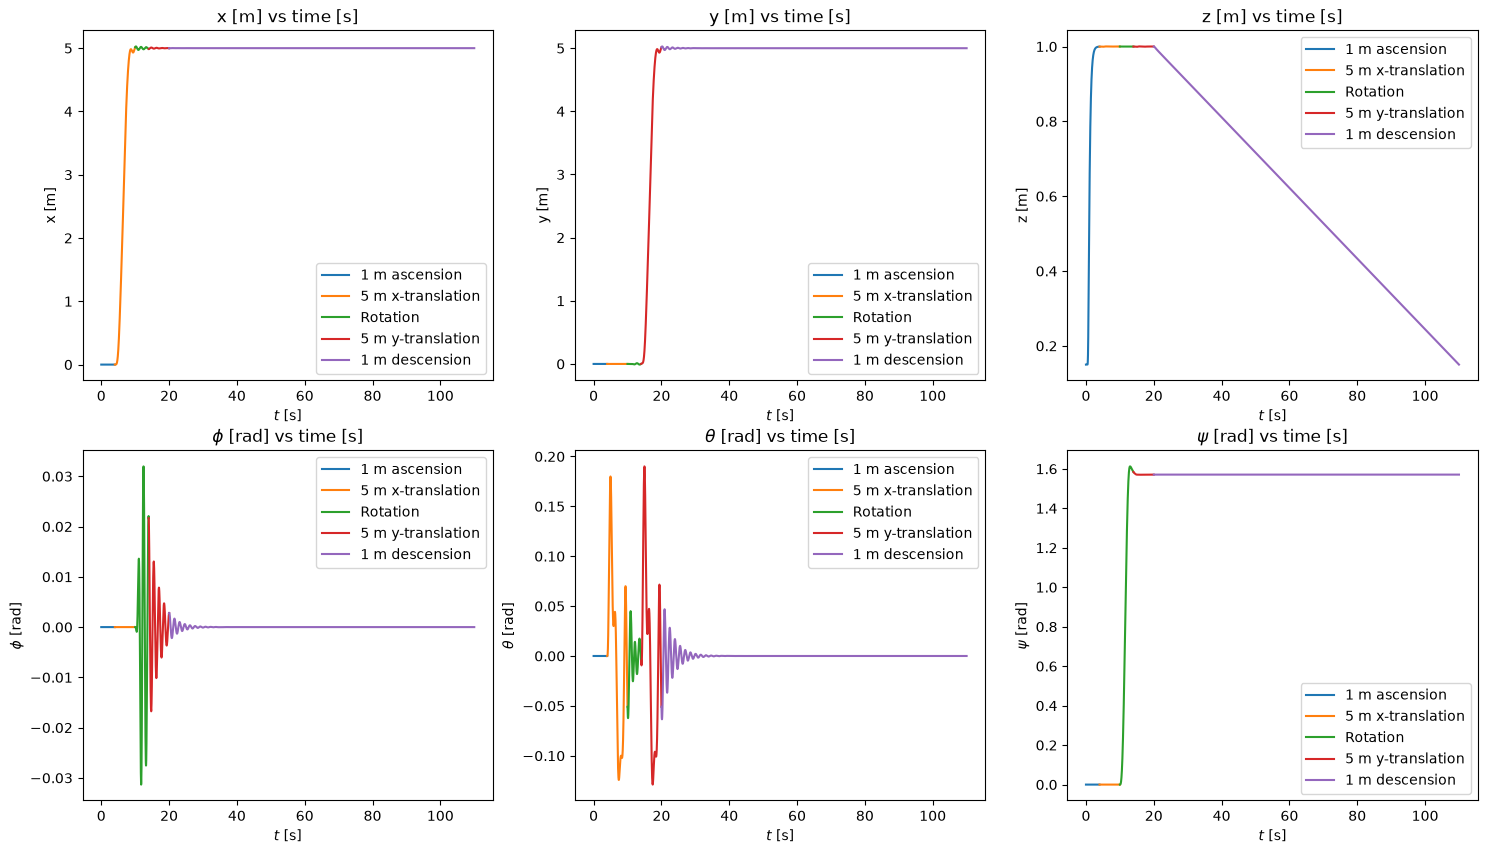

In [ ]:
fig3 = plotDegreesOfFreedom(times_a, r_ascend, '1 m ascension')
plotMoreDegreesOfFreedom(fig3, times_t1 + times_a[-1], r_trans1, '5 m x-translation')
plotMoreDegreesOfFreedom(fig3, times_y + times_a[-1] + times_t1[-1], r_yaw, 'Rotation')
plotMoreDegreesOfFreedom(fig3, times_t2 + times_a[-1] + times_t1[-1] + times_y[-1], r_trans2, '5 m y-translation')
plotMoreDegreesOfFreedom(fig3, times_d + times_a[-1] + times_t1[-1] + times_y[-1] + times_t2[-1], r_descend, '1 m descension')


In [ ]:
E_test3 = r_ascend[-1][16] + r_trans1[-1][16] + r_yaw[-1][16] + r_trans2[-1][16] + r_descend[-1][16]
E_left_test3 = E_available - E_test3
print(f'Energy Used: {E_test3} J')
print(f'Energy left: {E_left_test3} J')
print('The drone succesfully goes through the third performance goal without running out of energy.')

Energy Used: 23289.241995552813 J
Energy left: 147206.75800444718 J
The drone succesfully goes through the third performance goal without running out of energy.
